In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",       "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",      "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",     "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib",  "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("torch",       "torch==2.6.0",          "torch==2.6.0"),
    ("transformers", "transformers==5.5.3",   "transformers==5.5.3"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# [DEMO] Bài 5: Phát hiện Tấn công ICS bằng SecBERT (Pre-trained, Reconstruction)

**Mục tiêu:** Huấn luyện mô hình SecBERT pre-trained theo tiếp cận **reconstruction-based**:
- Train trên dữ liệu bình thường: predict `X[i+1]` từ `X[i-HISTORY:i]`
- Phát hiện tấn công: reconstruction error cao → vượt ngưỡng → báo động

**Pipeline:**
```
Train: train_dataset.csv (bình thường) → MSE + smoothness loss
Test : reconstruction_errors → grid search (percentile × window) → best threshold
```

## Phần 1: Import thư viện

In [22]:
# !pip install transformers torch scikit-learn matplotlib pandas -q

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, confusion_matrix, roc_auc_score,
                              roc_curve, ConfusionMatrixDisplay)
import warnings; warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from transformers import BertModel

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


## Phần 2: Tải Dữ liệu

In [23]:
# Tải dữ liệu BATADAL
train_df = pd.read_csv('data/BATADAL/train_dataset.csv', index_col=0)
test1_df = pd.read_csv('data/BATADAL/test_dataset_1.csv', index_col=0)
test2_df = pd.read_csv('data/BATADAL/test_dataset_2.csv', index_col=0)

drop_cols = ['DATETIME', 'ATT_FLAG',
             'PRESSURE_J415', 'PRESSURE_J317', 'STATUS_PU6', 'FLOW_PU6']
feat_cols  = [c for c in train_df.columns if c not in drop_cols]
input_dim  = len(feat_cols)
print(f'Số cảm biến (input_dim): {input_dim}')

# Chuẩn hóa: fit trên train_dataset (bình thường), transform test
scaler = StandardScaler()
Xfull  = scaler.fit_transform(train_df[feat_cols].values)
Xtest1 = scaler.transform(test1_df[feat_cols].values)
Xtest2 = scaler.transform(test2_df[feat_cols].values)
Ytest1 = test1_df['ATT_FLAG'].values
Ytest2 = test2_df['ATT_FLAG'].values

print(f'Xfull  : {Xfull.shape}  (train — bình thường)')
print(f'Xtest1 : {Xtest1.shape}  attacks={Ytest1.sum()} ({100*Ytest1.mean():.1f}%)')
print(f'Xtest2 : {Xtest2.shape}  attacks={Ytest2.sum()} ({100*Ytest2.mean():.1f}%)')

Số cảm biến (input_dim): 39
Xfull  : (48106, 39)  (train — bình thường)
Xtest1 : (18433, 39)  attacks=1968.0 (10.7%)
Xtest2 : (10081, 39)  attacks=1628.0 (16.1%)


## Phần 3: Tạo Sequences

Mô hình học dự đoán timestep kế tiếp:
```
Input:  X[i-HISTORY:i]  →  Output: X[i+1]
```
Khi gặp pattern tấn công (bất thường), mô hình dự đoán sai → reconstruction error cao → phát hiện.

In [24]:
# ── Tạo sequences: input X[i-HISTORY:i] → target X[i+1] ──────────────────────
# Giảm HISTORY và N_TRAIN so với cấu hình GPU để phù hợp CPU.
HISTORY = 50
N_TRAIN = 6000

all_idxs = np.arange(HISTORY, len(Xfull) - 1)
train_idxs, val_idxs, _, _ = train_test_split(
    all_idxs, all_idxs, test_size=0.2, random_state=42, shuffle=True)

rng = np.random.default_rng(42)
train_idxs = rng.choice(train_idxs, size=min(N_TRAIN, len(train_idxs)), replace=False)

train_seq = np.array([Xfull[i - HISTORY : i]  for i in train_idxs], dtype=np.float32)
train_tgt = np.array([Xfull[i + 1]            for i in train_idxs], dtype=np.float32)
val_seq   = np.array([Xfull[i - HISTORY : i]  for i in val_idxs],   dtype=np.float32)
val_tgt   = np.array([Xfull[i + 1]            for i in val_idxs],   dtype=np.float32)

print(f'train_seq: {train_seq.shape}  val_seq: {val_seq.shape}')

train_seq: (6000, 50, 39)  val_seq: (9611, 50, 39)


In [25]:
class TimeSeriesDataset(Dataset):
    def __init__(self, sequences, targets):
        self.sequences = torch.tensor(sequences, dtype=torch.float32)
        self.targets   = torch.tensor(targets,   dtype=torch.float32)
    def __len__(self):  return len(self.sequences)
    def __getitem__(self, idx):
        return {'inputs': self.sequences[idx], 'targets': self.targets[idx]}

BATCH_SIZE   = 64
train_loader = DataLoader(TimeSeriesDataset(train_seq, train_tgt),
                          batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TimeSeriesDataset(val_seq,   val_tgt),
                          batch_size=BATCH_SIZE, shuffle=False)
print(f'Train batches: {len(train_loader)}  Val batches: {len(val_loader)}')

Train batches: 94  Val batches: 151


## Phần 4: Kiến trúc `TimeSeriesBERTFineTune`

In [26]:
class TimeSeriesBERTFineTune(nn.Module):
    """
    Kiến trúc: Linear projection → Sinusoidal PE → CLS token → SecBERT → output_layer
    Task: dự đoán timestep tiếp theo (reconstruction-based anomaly detection).
    """
    MODEL_NAME = 'jackaduma/SecBERT'

    def __init__(self, input_dim, hidden_size=768, seq_len=50, output_dim=None):
        super().__init__()
        if output_dim is None:
            output_dim = input_dim

        # 1. Linear projection: features → BERT hidden space
        self.embedding = nn.Linear(input_dim, hidden_size)

        # 2. Sinusoidal Positional Encoding
        pe = self._sinusoidal_pe(seq_len + 1, hidden_size)
        self.register_buffer('pos_embedding', pe)

        # 3. Learnable CLS token
        self.cls_token = nn.Parameter(torch.empty(1, 1, hidden_size))
        nn.init.trunc_normal_(self.cls_token, std=0.02)

        # 4. SecBERT encoder (pre-trained)
        print(f'Loading {self.MODEL_NAME} ...')
        self.bert = BertModel.from_pretrained(self.MODEL_NAME)

        # Freeze 10 lớp đầu, fine-tune 2 lớp cuối
        for param in self.bert.parameters():
            param.requires_grad = False
        for layer in self.bert.encoder.layer[-2:]:
            for param in layer.parameters():
                param.requires_grad = True

        # 5. Output: predict next timestep
        self.output_layer = nn.Linear(hidden_size, output_dim)

    @staticmethod
    def _sinusoidal_pe(seq_len, hidden_dim):
        position = torch.arange(0, seq_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, hidden_dim, 2) * (-math.log(10000.0) / hidden_dim))
        pe = torch.zeros(seq_len, hidden_dim)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        return pe.unsqueeze(0)

    def forward(self, x):
        batch_size = x.size(0)
        x   = self.embedding(x)
        cls = self.cls_token.expand(batch_size, 1, -1)
        x   = torch.cat([cls, x], dim=1)
        x   = x + self.pos_embedding[:, :x.size(1)]
        attn_mask = torch.ones(batch_size, x.size(1), dtype=torch.long, device=x.device)
        outputs   = self.bert(inputs_embeds=x, attention_mask=attn_mask)
        cls_state = outputs.last_hidden_state[:, 0, :]
        return self.output_layer(cls_state)

    def compute_loss(self, predictions, targets, lambda_smooth=0.1):
        """MSE loss + smoothness regularization."""
        mse_loss        = nn.MSELoss()(predictions, targets)
        loss_smoothness = torch.mean((predictions[:, 1:] - predictions[:, :-1]) ** 2)
        return mse_loss + lambda_smooth * loss_smoothness

    @torch.no_grad()
    def reconstruction_errors(self, X, device, batch_size=256):
        """
        Tính squared reconstruction error theo từng timestep.
        X: (N, input_dim) — dữ liệu test đã chuẩn hóa
        Returns: (N - HISTORY, input_dim)
        """
        self.eval()
        all_errors = []
        history    = self.pos_embedding.size(1) - 1
        start_idx  = history + 1
        for idx in range(start_idx, len(X), batch_size):
            batch_end = min(idx + batch_size, len(X))
            seqs  = np.stack([X[i - history : i] for i in range(idx, batch_end)])
            gts   = X[idx:batch_end]
            preds = self(torch.tensor(seqs, dtype=torch.float32, device=device)).cpu().numpy()
            all_errors.append((preds - gts) ** 2)
        return np.concatenate(all_errors, axis=0)


model = TimeSeriesBERTFineTune(
    input_dim=input_dim, hidden_size=768, seq_len=HISTORY, output_dim=input_dim
).to(device)

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable: {trainable:,} / Total: {total:,} ({100*trainable/total:.1f}%)')

Loading jackaduma/SecBERT ...
Trainable: 14,237,223 / Total: 83,512,359 (17.0%)


## Phần 5: Hàm Huấn luyện

In [27]:
def train_model(model, train_loader, val_loader, device,
                epochs=15, lr=5e-5, weight_decay=1e-4,
                early_stopping_patience=5):
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=2, verbose=False)
    criterion = nn.MSELoss()

    train_losses, val_losses = [], []
    best_val_loss, no_improve = float('inf'), 0

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            inputs  = batch['inputs'].to(device)
            targets = batch['targets'].to(device)
            loss    = model.compute_loss(model(inputs), targets, lambda_smooth=0.1)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
        avg_train = total_loss / len(train_loader)
        train_losses.append(avg_train)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                val_loss += criterion(model(batch['inputs'].to(device)),
                                      batch['targets'].to(device)).item()
        avg_val = val_loss / len(val_loader)
        val_losses.append(avg_val)
        scheduler.step(avg_val)

        print(f'Epoch {epoch+1:02d}/{epochs} | Train: {avg_train:.4f} | Val: {avg_val:.4f}')

        if avg_val < best_val_loss:
            best_val_loss, no_improve = avg_val, 0
            torch.save(model.state_dict(), 'best_secbert.pt')
        else:
            no_improve += 1
            if no_improve >= early_stopping_patience:
                print(f'Early stopping tại epoch {epoch+1}')
                break

    model.load_state_dict(torch.load('best_secbert.pt', map_location=device))
    return train_losses, val_losses

## Phần 6: Huấn luyện

Epoch 01/15 | Train: 0.5637 | Val: 0.2652
Epoch 02/15 | Train: 0.4039 | Val: 0.1798
Epoch 03/15 | Train: 0.3527 | Val: 0.1461
Epoch 04/15 | Train: 0.3294 | Val: 0.1325
Epoch 05/15 | Train: 0.3167 | Val: 0.1222
Epoch 06/15 | Train: 0.3193 | Val: 0.1173
Epoch 07/15 | Train: 0.3009 | Val: 0.1178
Epoch 08/15 | Train: 0.2949 | Val: 0.1133
Epoch 09/15 | Train: 0.2895 | Val: 0.1147
Epoch 10/15 | Train: 0.2831 | Val: 0.1100
Epoch 11/15 | Train: 0.2776 | Val: 0.1072
Epoch 12/15 | Train: 0.2727 | Val: 0.1057
Epoch 13/15 | Train: 0.2686 | Val: 0.1050
Epoch 14/15 | Train: 0.2660 | Val: 0.1041
Epoch 15/15 | Train: 0.2625 | Val: 0.1017


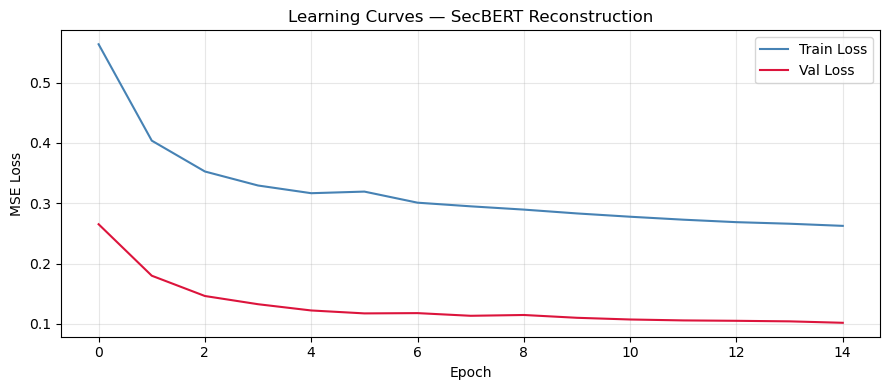

In [28]:
train_losses, val_losses = train_model(
    model, train_loader, val_loader, device,
    epochs=15, lr=5e-5, weight_decay=1e-4, early_stopping_patience=5)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(train_losses, label='Train Loss', color='steelblue')
ax.plot(val_losses,   label='Val Loss',   color='crimson')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
ax.set_title('Learning Curves — SecBERT Reconstruction')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## Phần 7: Tính Reconstruction Error

In [29]:
# ── Reconstruction errors trên validation split ───────────────────────────────
print('Tính reconstruction errors trên validation split của Xfull ...')
val_errors      = model.reconstruction_errors(Xfull[val_idxs.min():], device)
val_errors_mean = val_errors.mean(axis=1)
print(f'val_errors: {val_errors.shape}')
print(f'Mean error: {val_errors_mean.mean():.4f} ± {val_errors_mean.std():.4f}')

# ── Reconstruction errors trên test1 ─────────────────────────────────────────
print('\nTính reconstruction errors trên test_dataset_1 ...')
test1_errors      = model.reconstruction_errors(Xtest1, device)
test1_errors_mean = test1_errors.mean(axis=1)
Ytest1_clipped    = Ytest1[HISTORY + 1 : HISTORY + 1 + len(test1_errors_mean)]
print(f'test1_errors: {test1_errors.shape}  labels: {len(Ytest1_clipped)}')

Tính reconstruction errors trên validation split của Xfull ...
val_errors: (48004, 39)
Mean error: 0.1358 ± 2.5909

Tính reconstruction errors trên test_dataset_1 ...
test1_errors: (18382, 39)  labels: 18382


## Phần 8: Grid Search Threshold

Best F1: 0.9570  theta: 0.2180  window: 5


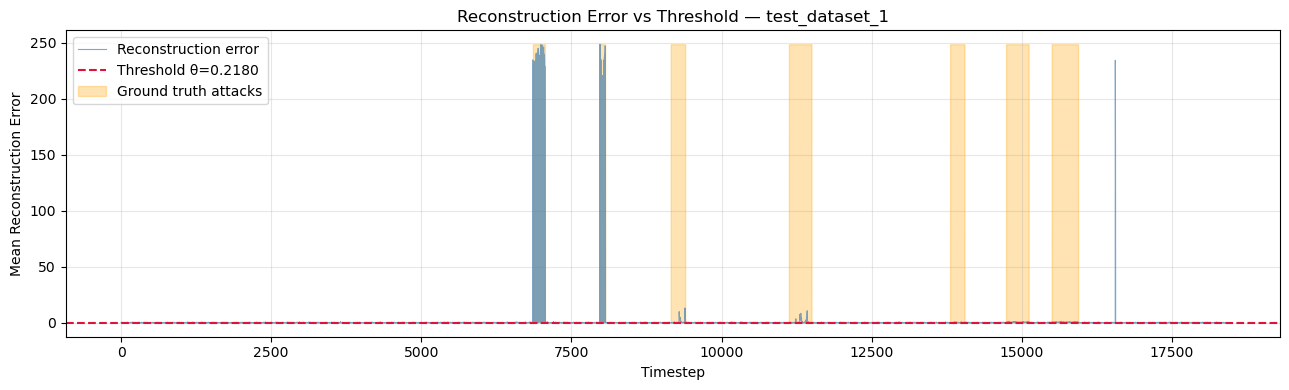

In [30]:
# ── Grid search: percentile × window ─────────────────────────────────────────
percentiles = [0.90, 0.92, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99]
windows     = [1, 3, 5, 10, 20]

best_f1, best_theta, best_window = -1, None, 1

for p in percentiles:
    theta = np.quantile(val_errors_mean, p)
    for w in windows:
        if w == 1:
            Yhat = (test1_errors_mean > theta).astype(int)
        else:
            Yhat = (np.convolve(test1_errors_mean > theta, np.ones(w), 'same') // w).astype(int)
        n  = min(len(Yhat), len(Ytest1_clipped))
        f1 = f1_score(Ytest1_clipped[:n], Yhat[:n], average='micro', zero_division=0)
        if f1 > best_f1:
            best_f1, best_theta, best_window = f1, theta, w

print(f'Best F1: {best_f1:.4f}  theta: {best_theta:.4f}  window: {best_window}')

plt.figure(figsize=(13, 4))
plt.plot(test1_errors_mean, color='steelblue', alpha=0.7, linewidth=0.8, label='Reconstruction error')
plt.axhline(best_theta, color='crimson', linestyle='--', linewidth=1.5, label=f'Threshold θ={best_theta:.4f}')
plt.fill_between(range(len(Ytest1_clipped)), 0, test1_errors_mean.max() * Ytest1_clipped,
                 alpha=0.3, color='orange', label='Ground truth attacks')
plt.xlabel('Timestep'); plt.ylabel('Mean Reconstruction Error')
plt.title('Reconstruction Error vs Threshold — test_dataset_1')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

## Phần 9: Đánh giá trên Test 2 (Held-out)

Tính reconstruction errors trên test_dataset_2 ...
=== SecBERT Reconstruction (Test2) ===
  F1 (micro): 0.9263  |  AUC-ROC: 0.8612
  theta=0.2180, window=5


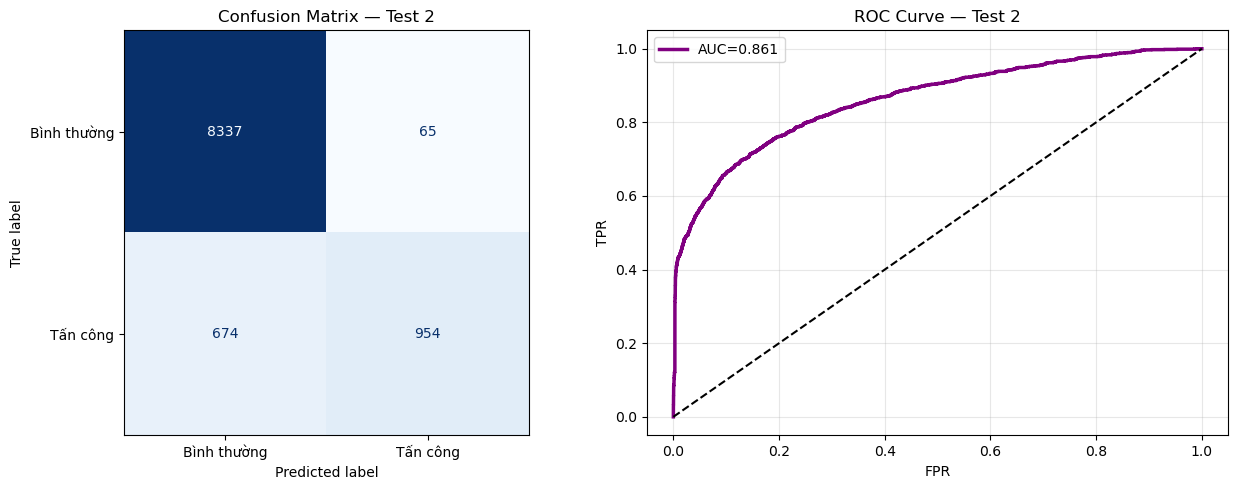

In [31]:
# ── Đánh giá trên test_dataset_2 (held-out) ──────────────────────────────────
print('Tính reconstruction errors trên test_dataset_2 ...')
test2_errors      = model.reconstruction_errors(Xtest2, device)
test2_errors_mean = test2_errors.mean(axis=1)
Ytest2_clipped    = Ytest2[HISTORY + 1 : HISTORY + 1 + len(test2_errors_mean)]

if best_window == 1:
    Yhat2 = (test2_errors_mean > best_theta).astype(int)
else:
    Yhat2 = (np.convolve(test2_errors_mean > best_theta,
                         np.ones(best_window), 'same') // best_window).astype(int)
n     = min(len(Yhat2), len(Ytest2_clipped))
Yhat2, Yt2 = Yhat2[:n], Ytest2_clipped[:n]

f1  = f1_score(Yt2, Yhat2, average='micro', zero_division=0)
auc = roc_auc_score(Yt2, test2_errors_mean[:n])
print(f'=== SecBERT Reconstruction (Test2) ===')
print(f'  F1 (micro): {f1:.4f}  |  AUC-ROC: {auc:.4f}')
print(f'  theta={best_theta:.4f}, window={best_window}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(Yt2, Yhat2),
                       display_labels=['Bình thường', 'Tấn công']).plot(
    ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix — Test 2')
fpr, tpr, _ = roc_curve(Yt2, test2_errors_mean[:n])
axes[1].plot(fpr, tpr, color='purple', linewidth=2.5, label=f'AUC={auc:.3f}')
axes[1].plot([0,1],[0,1],'k--')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve — Test 2'); axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## Kết luận

**SecBERT Reconstruction-based Anomaly Detection:**
- Huấn luyện trên dữ liệu bình thường → học pattern bình thường của hệ thống ICS
- Phát hiện tấn công bằng reconstruction error cao (tấn công → pattern lạ → BERT dự đoán sai)
- Grid search `percentile × window` tự động tìm ngưỡng tối ưu

**Ưu điểm so với supervised (B7/B8):**
- Không cần nhãn tấn công khi huấn luyện
- Phát hiện được tấn công mới chưa từng thấy (novel attacks)
- Pre-trained BERT mang lại khả năng mô hình hóa chuỗi thời gian mạnh

**Lưu ý kỹ thuật:**
- `HISTORY=50`, `N_TRAIN=6000`: giảm so với cấu hình GPU để phù hợp CPU
- Thời gian train ≈ 30–60 phút (CPU) hoặc 3–8 phút (GPU)